# Task 05: Conventional ML Forecasting with XGBoost

This notebook presents the already-generated Task 05 artifacts. It does **not** train models. Run `scripts/run_xgboost.py --full` separately only after approving the estimated CPU and memory requirements.

## 1. Experiment safeguards

XGBoost uses each sensor's own preceding 12 standardized speeds, zero and finite indicators, target-time sine/cosine features, and categorical sensor identity. Normalization is fitted on training rows only. Hyperparameters are selected on validation MAE only. No adjacency, graph distance, neighbouring-sensor speed, or future observed speed is used. Exact-zero targets are excluded from primary training and evaluation, with all finite targets retained as a sensitivity evaluation.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'requirements.txt').is_file() and (candidate / 'src').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the project root from the current working directory.')

ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(ROOT))

metrics_path = ROOT / 'results' / 'task05_xgboost' / 'metrics.json'
selection_path = ROOT / 'results' / 'task05_xgboost' / 'validation_trials.json'
baseline_path = ROOT / 'results' / 'task04_baselines' / 'metrics.json'
missing = [path for path in (metrics_path, selection_path, baseline_path) if not path.exists()]
if missing:
    raise FileNotFoundError(
        'Required experiment artifacts are missing. Run the owner-approved full command first: '
        '.venv/Scripts/python.exe scripts/run_xgboost.py --full. Missing: '
        + ', '.join(str(path.relative_to(ROOT)) for path in missing)
    )

## 2. Configuration and validation-only model selection

In [2]:
selection = json.loads(selection_path.read_text(encoding='utf-8'))
trials = pd.DataFrame(selection['trials'])
display(pd.Series({
    'selected_candidate': selection['selected_candidate'],
    'seed': selection['seed'],
    'threads': selection['nthread'],
    'feature_count': selection['feature_count'],
    'elapsed_seconds': selection['elapsed_seconds'],
}))
display(trials.sort_values(['candidate', 'horizon_minutes']))
display(pd.DataFrame(selection['target_counts']).T)
assert set(trials['horizon_minutes']) == {15, 30, 60}
assert selection['tie_breaking'] == 'lowest mean three-horizon validation MAE, then candidate name'

selected_candidate    depth8_eta005
seed                         268513
threads                           4
feature_count                    39
elapsed_seconds         4107.976115
dtype: object

,candidate,best_iteration_zero_based,boosting_rounds,validation_mae_mph,horizon_minutes
0,depth6_eta005,998,999,2.857348,15
3,depth6_eta005,999,1000,3.398094,30
6,depth6_eta005,999,1000,4.023998,60
2,depth6_eta010_regularized,973,974,2.858885,15
5,depth6_eta010_regularized,997,998,3.396744,30
8,depth6_eta010_regularized,996,997,4.025262,60
1,depth8_eta005,786,787,2.827610,15
4,depth8_eta005,992,993,3.342841,30
7,depth8_eta005,993,994,3.937333,60


,train_included,train_excluded,validation_included,validation_excluded
15,4607441,353728,657752,49360
30,4607439,353730,657743,49369
60,4607444,353725,657751,49361


## 3. Locked test metrics and baseline comparison

In [3]:
task05 = json.loads(metrics_path.read_text(encoding='utf-8'))
task04 = json.loads(baseline_path.read_text(encoding='utf-8'))
xgb_metrics = pd.DataFrame(task05['metrics'])
baseline_metrics = pd.DataFrame(task04['metrics'])
comparison = pd.concat([baseline_metrics, xgb_metrics], ignore_index=True)
primary = comparison[comparison['mask_policy'] == 'finite_nonzero_targets']
display(primary.pivot(index='model', columns='horizon', values=['mae_mph', 'rmse_mph']).round(4))
assert task05['baseline_alignment_verified'] is True
assert set(xgb_metrics['horizon']) == {'+15', '+30', '+60'}

mae_mph                 rmse_mph                  
horizon                +15     +30     +60      +15      +30      +60
model                                                                
historical_average  7.1104  7.1104  7.1108   9.8311   9.8311   9.8313
persistence         4.0175  5.0952  6.7980   8.6955  11.1353  14.2136
xgboost             3.0044  3.5235  4.0866   5.4669   6.4889   7.4888

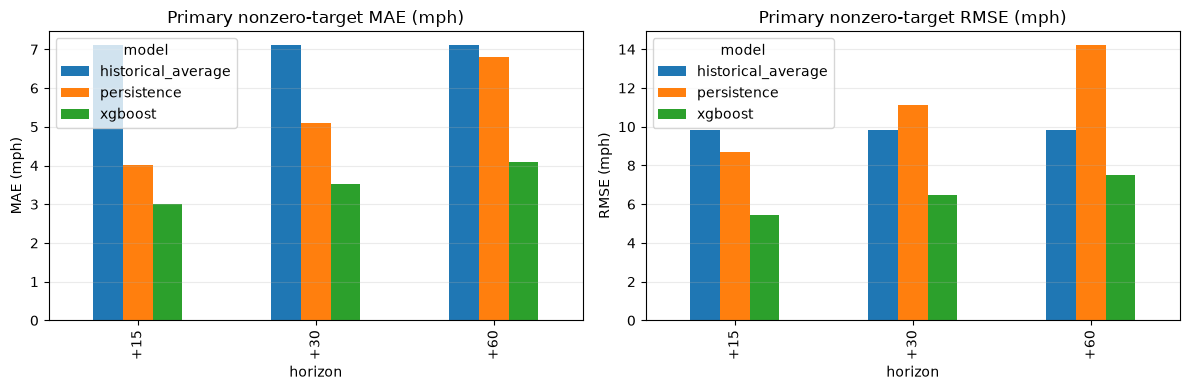

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for axis, metric, label in zip(axes, ['mae_mph', 'rmse_mph'], ['MAE (mph)', 'RMSE (mph)']):
    primary.pivot(index='horizon', columns='model', values=metric).loc[['+15', '+30', '+60']].plot.bar(ax=axis)
    axis.set_ylabel(label)
    axis.set_title(f'Primary nonzero-target {label}')
    axis.grid(axis='y', alpha=0.25)
plt.tight_layout()

## 4. Zero-target sensitivity

In [5]:
display(comparison.pivot(index=['model', 'horizon'], columns='mask_policy', values=['mae_mph', 'rmse_mph']).round(4))
assert set(comparison['mask_policy']) == {
    'finite_nonzero_targets', 'all_finite_targets_including_zeros'
}
selection['input_finite_indicator']

mae_mph  \
mask_policy                all_finite_targets_including_zeros   
model              horizon                                      
historical_average +15                                12.9528   
                   +30                                12.9534   
                   +60                                12.9551   
persistence        +15                                 4.0564   
                   +30                                 5.3787   
                   +60                                 7.4254   
xgboost            +15                                 9.5093   
                   +30                                 9.9989   
                   +60                                10.5082   

                                                   \
mask_policy                finite_nonzero_targets   
model              horizon                          
historical_average +15                     7.1104   
                   +30                     7.1104   
                   +60                     7.1108   
persistence        +15                     4.0175   
                   +30                     5.0952   
                   +60                     6.7980   
xgboost            +15                     3.0044   
                   +30                     3.5235   
                   +60                     4.0866   

                                                     rmse_mph  \
mask_policy                all_finite_targets_including_zeros   
model              horizon                                      
historical_average +15                                21.6593   
                   +30                                21.6603   
                   +60                                21.6624   
persistence        +15                                 9.9299   
                   +30                                12.8079   
                   +60                                16.3345   
xgboost            +15                                20.7035   
                   +30                                21.0911   
                   +60                                21.4319   

                                                   
mask_policy                finite_nonzero_targets  
model              horizon                         
historical_average +15                     9.8311  
                   +30                     9.8311  
                   +60                     9.8313  
persistence        +15                     8.6955  
                   +30                    11.1353  
                   +60                    14.2136  
xgboost            +15                     5.4669  
                   +30                     6.4889  
                   +60                     7.4888

{'nonfinite_observation_count': 0,
 'constant_on_verified_metr_la': True,
 'purpose': 'Retained for preprocessing-contract consistency and future datasets with missing inputs.'}

## 5. Feature importance (descriptive, not causal)

Gain importance describes how the fitted trees used features. It does not establish that a feature causes traffic changes, and correlated lag features can divide importance among themselves.

In [6]:
importance_rows = []
for horizon in (15, 30, 60):
    booster = xgb.Booster()
    booster.load_model(ROOT / 'artifacts' / 'task05_xgboost' / 'models' / f'horizon_{horizon}.json')
    for feature, gain in booster.get_score(importance_type='gain').items():
        importance_rows.append({'horizon_minutes': horizon, 'feature': feature, 'gain': gain})
importance = pd.DataFrame(importance_rows)
top = importance.sort_values(['horizon_minutes', 'gain'], ascending=[True, False]).groupby('horizon_minutes').head(10)
display(top)

,horizon_minutes,feature,gain
11,15,speed_lag_1,150577.562500
23,15,zero_lag_1,63105.496094
26,15,sensor_id,35144.515625
22,15,zero_lag_2,19582.835938
10,15,speed_lag_2,17461.628906
21,15,zero_lag_3,9534.771484
25,15,target_time_cos,7844.588867
9,15,speed_lag_3,7511.436523
8,15,speed_lag_4,4736.362305
20,15,zero_lag_4,4372.879883


## 6. Runtime, limitations, and interpretation

The conventional model is deliberately local-history-only. A later ST-GNN may additionally consume neighbouring observations and network structure, so any improvement will describe the value of spatially informed modelling relative to this local-history comparison; it will not by itself isolate a causal graph effect. The finite-input indicators are retained by contract even when constant on the verified METR-LA file. Review the recorded runtime, model sizes, target exclusions, and zero-inclusive sensitivity results before drawing conclusions.

In [7]:
model_sizes = {
    horizon: (ROOT / 'artifacts' / 'task05_xgboost' / 'models' / f'horizon_{horizon}.json').stat().st_size
    for horizon in (15, 30, 60)
}
display(pd.Series(model_sizes, name='model_size_bytes'))
assert task05['data_sha256'] == task04['data_sha256']
assert task05['split_policy'] == task04['split_policy']
assert all(size > 0 for size in model_sizes.values())
print('Task 05 artifacts, alignment, horizons, policies, and model files verified.')

15    46532273
30    55815633
60    56618698
Name: model_size_bytes, dtype: int64

Task 05 artifacts, alignment, horizons, policies, and model files verified.
